# Phase 2B | Optogenetic-response validation and falsification

**DANDI 000568 | Two recording-session directions | GRU + TCN light ablations | Shuffled-light negative control | Isolated pulse analysis**

**Question:** Do recorded optical stimulation features improve predictions of future neural firing activity on a held-out recording session, beyond neural-history information alone?

This experiment makes **conditional predictions** from an offline *observed future stimulation schedule* (next 100 ms). It does **not** establish causal effects of light, safe control, epilepsy suppression, patient-specific models, or cross-animal generalization. **Both sessions are from one mouse.**

**Dataset:** Two small, `+ogen`, `no-raw-data` NWB assets from DANDI 000568, pinned version `0.230705.1633`. Approximately 73 MB total. Kaggle settings: **Internet ON**; CPU is adequate; GPU optional. **No additional Kaggle Input** required.

**Success for this validation study:** improvements from light-aware models should repeat in both train/test directions, be visible in the light-active subgroup, and should weaken under an optical-feature permutation sensitivity test. Improvements alone still do *not* prove causation.

Dataset: https://dandiarchive.org/dandiset/000568

## 1 | Configuration

Start with `QUICK_MODE = True` to verify the workflow. Later rerun with `QUICK_MODE = False` for larger sample caps and longer training. **Report which mode produced the numbers.** Validation remains within the training session separated by a temporal gap; the whole other session is kept for testing. Repeated windows are not biologically independent.

In [1]:
import sys, subprocess, importlib.util
for package, module in [("requests","requests"),("h5py","h5py"),("numpy","numpy"),
                        ("pandas","pandas"),("matplotlib","matplotlib"),
                        ("scikit-learn","sklearn"),("xgboost","xgboost"),("torch","torch")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package])

from pathlib import Path
from datetime import datetime, timezone
import os, json, re, zipfile, warnings, copy, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, h5py
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED=42
np.random.seed(SEED); random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(2)
QUICK_MODE = True
PILOT_MODE = QUICK_MODE
BIN_SEC = 0.020           # 20-ms bins, comparable to ~19-ms pulses
HISTORY_BINS = 50        # 1.0 second observed history
HORIZON_BINS = 5         # predict NEXT 100-ms population rate
EPOCHS = 8 if QUICK_MODE else 18
CAPS = {'train':6000,'val':1500,'test':3000} if QUICK_MODE else {'train':22000,'val':4500,'test':8000}
RUN_TWO_FOLDS = True    # Always test session 9 -> 12 AND session 12 -> 9
BATCH_SIZE = 256
BASE = 'https://api.dandiarchive.org'
DANDISET = '000568'; VERSION = '0.230705.1633'
ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/mnt/data')
OUT = ROOT/'phase2b_outputs'; CACHE = ROOT/'phase2b_nwb_cache'
OUT.mkdir(parents=True, exist_ok=True); CACHE.mkdir(parents=True, exist_ok=True)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE,'QUICK_MODE:',QUICK_MODE,'EPOCHS:',EPOCHS,'CAPS:',CAPS,'Output:',OUT)
print('Important: we predict neural firing rate, NOT clinical seizures.')
from datetime import datetime, timezone
from scipy.stats import spearmanr
import hashlib

Device: cuda QUICK_MODE: True EPOCHS: 8 CAPS: {'train': 6000, 'val': 1500, 'test': 3000} Output: /kaggle/working/phase2b_outputs
Important: we predict neural firing rate, NOT clinical seizures.


## 2 | Download just two small NWB files

The archive asset manifest is pinned. The code refuses accidental downloads of large raw recordings and caches the ~29 MB and ~44 MB files locally for re-use within a Kaggle session.

In [2]:
def api_json(url):
    response = requests.get(url, timeout=(15, 60), headers={'Accept':'application/json'})
    response.raise_for_status()
    return response.json()

assets=[]
url=f'{BASE}/api/dandisets/{DANDISET}/versions/{VERSION}/assets/'
while url:
    data=api_json(url); assets.extend(data['results']); url=data.get('next')
manifest=pd.DataFrame([{'asset_id':a['asset_id'],'path':a['path'],'size_bytes':a['size']} for a in assets])
small=manifest[(manifest.path.str.endswith('.nwb')) &
               (manifest.path.str.contains('no-raw-data',regex=False)) &
               (manifest.path.str.contains('+ogen',regex=False)) &
               (manifest.size_bytes < 70_000_000)].sort_values('size_bytes')
print('Available small +ogen NWB files:',len(small))
print(small[['path','size_bytes']].to_string(index=False))
if len(small)<2: raise RuntimeError('Fewer than 2 small optogenetic NWB files in pinned manifest')
selected=small.head(2).copy()
if len(set(selected.path.str.extract(r'(sess\d+)')[0].dropna()))<2:
    raise RuntimeError('Selected files do not appear to describe two distinct sessions')

def download_small(row):
    if not str(row['path']).endswith('.nwb') or '+ogen' not in str(row['path']) or 'no-raw-data' not in str(row['path']):
        raise ValueError('Refusing an unexpected or raw-data asset')
    nbytes=int(row['size_bytes'])
    if nbytes > 70_000_000: raise ValueError('Safety cap exceeded: 70 MB per file')
    target=CACHE/str(row['path']).split('/')[-1]
    if target.exists() and target.stat().st_size==nbytes:
        print('Reusing:',target.name); return target
    url=f"{BASE}/api/assets/{row['asset_id']}/download/"
    temporary=target.with_suffix('.nwb.part')
    with requests.get(url, stream=True, timeout=(30,180)) as response:
        response.raise_for_status()
        with temporary.open('wb') as f:
            for block in response.iter_content(chunk_size=1024*1024):
                if block: f.write(block)
    if temporary.stat().st_size != nbytes:
        raise IOError('Asset download size mismatch')
    temporary.replace(target)
    print('Downloaded',target.name,'MB:',round(nbytes/1e6,2))
    return target

paths={}
for _, row in selected.iterrows():
    match=re.search(r'sess(\d+)', str(row['path']))
    if not match: raise ValueError('Cannot identify session in '+str(row['path']))
    paths['session_'+match.group(1)]=download_small(row)
print('Selected sessions:',sorted(paths))
if len(paths)!=2: raise RuntimeError('Expected two distinct sessions')

Available small +ogen NWB files: 2
                                                                                      path  size_bytes
sub-fCamk1/sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb    28678484
 sub-fCamk1/sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb    44441669
Downloaded sub-fCamk1_ses-fCamk1-200901-sess12-no-raw-data_behavior+ecephys+image+ogen.nwb MB: 28.68
Downloaded sub-fCamk1_ses-fCamk1-200827-sess9-no-raw-data_behavior+ecephys+image+ogen.nwb MB: 44.44
Selected sessions: ['session_12', 'session_9']


## 3 | Extract optical pulses and neural-unit spikes

We treat optical action values as **binary light occupancy**, not calibrated watts. Pulse onsets are reconstructed from positive/zero transitions in NWB `OptogeneticSeries`. A time-axis overlap check alone does **not** prove sub-millisecond synchronization.

In [3]:
def as_text(x):
    return x.decode('utf-8','replace') if isinstance(x, bytes) else str(x)

def read_pulses(hf, label):
    root=hf.get('/stimulus/presentation')
    if root is None: raise ValueError('No /stimulus/presentation group')
    rows=[]
    for name,group in root.items():
        if not isinstance(group,h5py.Group) or not name.startswith('OptogeneticSeriesSite'):
            continue
        if 'data' not in group or 'timestamps' not in group:
            continue
        ts=np.asarray(group['timestamps'][:],dtype=np.float64)
        values=np.asarray(group['data'][:],dtype=np.float64).reshape(-1)
        if len(ts)!=len(values) or len(ts)<3 or not np.all(np.diff(ts)>=0):
            warnings.warn(f'{label}/{name} invalid timestamps or values'); continue
        flag=np.isfinite(values) & (values>0)
        starts=np.flatnonzero(flag & ~np.r_[False,flag[:-1]])
        ends=np.flatnonzero(~flag & np.r_[False,flag[:-1]])
        if flag[0]: starts=starts[1:]  # left-censored: do not invent its onset
        indices=np.searchsorted(ends,starts,side='right')
        valid=indices<len(ends)
        for i,j in zip(starts[valid],ends[indices[valid]]):
            if ts[j]<=ts[i]: continue
            rows.append({'session':label,'site':name.replace('OptogeneticSeries',''),
                         'onset_sec':float(ts[i]),'offset_sec':float(ts[j]),
                         'duration_sec':float(ts[j]-ts[i]),'raw_positive_code':float(values[i]),
                         'reported_unit':as_text(group['data'].attrs.get('unit','unknown'))})
    df=pd.DataFrame(rows)
    if df.empty: raise RuntimeError('No complete pulse ON/OFF intervals found in '+label)
    return df

def fractional_occupancy(onsets,offsets,n_bins,bin_sec=BIN_SEC):
    """Fraction of each time bin illuminated, clipped to [0,1]."""
    out=np.zeros(n_bins,dtype=np.float64)
    starts=np.asarray(onsets,dtype=np.float64); ends=np.asarray(offsets,dtype=np.float64)
    valid=np.isfinite(starts)&np.isfinite(ends)&(ends>starts)&(starts>=0)&(ends<(n_bins*bin_sec))
    starts=starts[valid]; ends=ends[valid]
    if not len(starts): return out.astype(np.float32)
    a=np.floor(starts/bin_sec).astype(np.int64)
    b=np.floor(np.nextafter(ends,-np.inf)/bin_sec).astype(np.int64)
    same=(a==b)
    np.add.at(out,a[same],(ends[same]-starts[same])/bin_sec)
    cross=~same
    np.add.at(out,a[cross],((a[cross]+1)*bin_sec-starts[cross])/bin_sec)
    np.add.at(out,b[cross],(ends[cross]-b[cross]*bin_sec)/bin_sec)
    # Add fully illuminated intermediate bins via range increments.
    diff=np.zeros(n_bins+1,dtype=np.float64)
    np.add.at(diff,a[cross]+1,1.0)
    np.add.at(diff,b[cross],-1.0)
    out+=np.cumsum(diff[:-1])
    return np.clip(out,0.0,1.0).astype(np.float32)

def read_session(label,file_path):
    with h5py.File(file_path,'r') as hf:
        if '/units/spike_times' not in hf or '/units/spike_times_index' not in hf:
            raise RuntimeError('Missing sorted unit spike times: '+label)
        spikes=np.asarray(hf['/units/spike_times'][:],dtype=np.float64)
        n_units=len(hf['/units/spike_times_index'])
        if not n_units or not len(spikes): raise RuntimeError('No neural spikes in '+label)
        spikes=spikes[np.isfinite(spikes)&(spikes>=0)]
        events=read_pulses(hf,label)
    if events.onset_sec.max()>spikes.max() or events.onset_sec.min()<spikes.min():
        raise RuntimeError('Light pulses outside spike time span: check clock alignment')
    n_bins=int(np.ceil(max(spikes.max(),float(events.offset_sec.max()))/BIN_SEC))+10
    indices=np.floor(spikes/BIN_SEC).astype(np.int64)
    counts=np.bincount(indices,minlength=n_bins).astype(np.float32)
    rate=counts/(n_units*BIN_SEC) # average spikes/s per sorted unit
    return {'session':label,'spikes':spikes,'n_units':n_units,'n_bins':n_bins,'rate':rate,'events':events}

sessions={label:read_session(label,path) for label,path in sorted(paths.items())}
SITES=sorted(set(pd.concat([s['events'] for s in sessions.values()],ignore_index=True).site))
for label,s in sessions.items():
    s['light']=np.column_stack([
        fractional_occupancy(s['events'].loc[s['events'].site==site,'onset_sec'],
                             s['events'].loc[s['events'].site==site,'offset_sec'],s['n_bins'])
        for site in SITES]).astype(np.float32)
    # History features: log(1+rate), site-specific optical occupancy, any-light occupancy.
    s['history_features']=np.column_stack([np.log1p(s['rate']),s['light'],s['light'].max(axis=1)]).astype(np.float32)
    print(label,': sorted units',s['n_units'],', spikes',len(s['spikes']),
          ', pulses',len(s['events']),', recording seconds',round(s['n_bins']*BIN_SEC))
all_events=pd.concat([s['events'] for s in sessions.values()],ignore_index=True)
all_events.to_csv(OUT/'pulse_events_from_real_NWB.csv',index=False)
print('Optical sites:',SITES)
print('Raw optical codes by session (DO NOT interpret as watts):')
print(all_events.groupby('session').raw_positive_code.unique().apply(lambda x:list(x)[:10]).to_string())

session_12 : sorted units 47 , spikes 1800735 , pulses 50309 , recording seconds 14810
session_9 : sorted units 57 , spikes 2259343 , pulses 42088 , recording seconds 17920
Optical sites: ['Site3', 'Site4', 'Site5', 'Site6', 'Site7', 'Site8']
Raw optical codes by session (DO NOT interpret as watts):
session
session_12    [62711.0, 62623.0, 62687.0, 62911.0, 63599.0]
session_9                                            [19.0]


## 4 | Leakage-conscious training/test windows

Every input uses the *past* 1 second of neural activity and the *recorded* next 100-ms optical schedule; every label measures the next 100-ms rate. The test recording is never used to fit models, choose hyperparameters, or estimate normalization. Training and validation are separated by a 20-second temporal gap. Candidate windows are balanced by presence/absence of future light, so this is **not a prevalence-representative sampling of neural activity**.

In [4]:
def make_splits(s,kind,cut_fraction=0.75):
    n=s['n_bins']; light=s['light']
    earliest=int(np.floor(s['events'].onset_sec.min()/BIN_SEC))
    latest=int(np.ceil(s['events'].offset_sec.max()/BIN_SEC))
    lo=max(HISTORY_BINS,earliest-int(30/BIN_SEC))
    hi=min(n-HORIZON_BINS-1,latest+int(30/BIN_SEC))
    if not (hi-lo > 100): raise ValueError('Stimulation epoch too short')
    if kind=='train_val':
        cut=int(lo+(hi-lo)*cut_fraction)
        gap=int(20/BIN_SEC) + HISTORY_BINS + HORIZON_BINS
        return (lo,cut-gap),(cut+gap,hi)
    return (lo,hi)

def pick_anchors(s,lo_hi,limit,seed):
    lo,hi=map(int,lo_hi)
    if hi<=lo+HISTORY_BINS: raise ValueError('Not enough time for sampled windows')
    mask=(s['light'].max(axis=1)>0).astype(np.int32)
    c=np.r_[0,np.cumsum(mask.astype(np.int64))]
    candidates=np.arange(lo,hi+1,dtype=np.int64)
    future_has_light=(c[candidates+HORIZON_BINS]-c[candidates])>0
    positives=candidates[future_has_light]
    negatives=candidates[~future_has_light]
    rng=np.random.default_rng(seed); rng.shuffle(positives); rng.shuffle(negatives)
    blocked=np.zeros(s['n_bins'],dtype=bool)
    selected=[]
    spacing=HORIZON_BINS+1
    target_each=limit//2
    def collect(pool,n_wanted):
        added=0
        for ix in pool:
            if added>=n_wanted: break
            if blocked[ix]: continue
            selected.append(int(ix)); added+=1
            blocked[max(0,ix-spacing):min(len(blocked),ix+spacing+1)]=True
        return added
    npos=collect(positives,target_each)
    nneg=collect(negatives,limit-npos)
    if len(selected)<limit:
        collect(positives,limit-len(selected))
    if len(selected)<limit:
        collect(negatives,limit-len(selected))
    return np.asarray(sorted(selected),dtype=np.int64)

def examples_at(s,anchors):
    a=np.asarray(anchors,dtype=np.int64)
    if not len(a): raise RuntimeError('No anchors selected')
    history_idxs=a[:,None]+np.arange(-HISTORY_BINS,0)[None,:]
    X=s['history_features'][history_idxs]
    site_light=s['light']
    actprefix=np.vstack([np.zeros((1,site_light.shape[1]),dtype=np.float64),
                         np.cumsum(site_light,dtype=np.float64,axis=0)])
    action=((actprefix[a+HORIZON_BINS]-actprefix[a])/HORIZON_BINS).astype(np.float32)
    rprefix=np.r_[0,np.cumsum(s['rate'],dtype=np.float64)]
    target=((rprefix[a+HORIZON_BINS]-rprefix[a])/HORIZON_BINS).astype(np.float32)
    prev=((rprefix[a]-rprefix[a-HORIZON_BINS])/HORIZON_BINS).astype(np.float32)
    has_action=(action.max(axis=1)>0)
    return {'X':X,'actions':action,'y':target,'persistence':prev,
            'light_future':has_action,'anchors':a,'session':s['session']}

def prepare_fold(train_s,test_s,seed=SEED):
    (train_rng,val_rng)=make_splits(train_s,'train_val')
    test_rng=make_splits(test_s,'test')
    a_train=pick_anchors(train_s,train_rng,CAPS['train'],seed)
    a_val=pick_anchors(train_s,val_rng,CAPS['val'],seed+1)
    a_test=pick_anchors(test_s,test_rng,CAPS['test'],seed+2)
    tr,va,te=examples_at(train_s,a_train),examples_at(train_s,a_val),examples_at(test_s,a_test)
    for name,e in [('train',tr),('val',va),('test',te)]:
        print(name,e['session'],len(e['y']),'light-active fraction',round(e['light_future'].mean(),3),
              'target mean Hz',round(float(np.mean(e['y'])),3))
    assert train_s['session']==tr['session']==va['session'] and train_s['session']!=te['session']
    assert tr['anchors'].max()+HISTORY_BINS+HORIZON_BINS < va['anchors'].min()
    return tr,va,te

labels=sorted(sessions)
# Run session 9 as train and 12 as test first, if both are present.
first= 'session_9' if 'session_9' in sessions else labels[0]
second='session_12' if 'session_12' in sessions else [x for x in labels if x!=first][0]
FOLDS=[(first,second)] + ([(second,first)] if RUN_TWO_FOLDS else [])
print('Training / held-out-session evaluation:',FOLDS)

Training / held-out-session evaluation: [('session_9', 'session_12'), ('session_12', 'session_9')]


## 5 | Models and matched light ablations

We train two versions of each model on **identical windows**:

* **NEURAL_ONLY:** All optical-history and optical-action features are masked *after standardization*; the GRU/TCN network structure remains identical.
* **NEURAL_PLUS_LIGHT:** Uses optical history and the recorded next-100-ms optical action schedule.

We also compare persistence, neural-only XGBoost, and optical-aware XGBoost. The same architecture/seed, train/validation windows, and preprocessing fit are used for the GRU/TCN light ablation pairs. This is still an observational comparison.

In [5]:
def xgb_features(ex,allow_light=True):
    rate=np.expm1(np.maximum(ex['X'][:,:,0],0))  # restore per-unit Hz from log(1+rate)
    pieces=[rate[:,-HORIZON_BINS:].mean(axis=1),
            rate[:,-10:].mean(axis=1),rate.mean(axis=1),
            rate.std(axis=1),rate.max(axis=1),
            (rate[:,-10:].mean(axis=1)-rate[:,:10].mean(axis=1))]
    if allow_light:
        # site light history and recorded light plan for the prediction horizon
        nsites=ex['actions'].shape[1]
        history=ex['X'][:,:,1:1+nsites]
        for k in range(nsites):
            pieces.extend([history[:,:,k].mean(axis=1),history[:,-5:,k].mean(axis=1),ex['actions'][:,k]])
    return np.column_stack(pieces).astype(np.float32)

def transforms_from_train(train):
    xm=train['X'].mean(axis=(0,1)); xs=train['X'].std(axis=(0,1)).clip(1e-3)
    am=train['actions'].mean(axis=0); ast=train['actions'].std(axis=0).clip(1e-3)
    ly=np.log1p(np.maximum(0,train['y']))
    ym=float(ly.mean()); ys=max(float(ly.std()),0.01)
    return {'xm':xm,'xs':xs,'am':am,'ast':ast,'ym':ym,'ys':ys}

def preprocess_dl(ex,sc,allow_light=True):
    X=np.clip((ex['X']-sc['xm'])/sc['xs'],-8,8).astype(np.float32)
    A=np.clip((ex['actions']-sc['am'])/sc['ast'],-8,8).astype(np.float32)
    Y=((np.log1p(np.maximum(0,ex['y']))-sc['ym'])/sc['ys']).astype(np.float32)
    if not allow_light:
        X[:,:,1:]=0.0  # optical channels neutral after standardization
        A[:]=0.0      # same action dimensions/architecture
    return X,A,Y

class GRUNet(nn.Module):
    def __init__(self,n_features,n_actions):
        super().__init__()
        self.rnn=nn.GRU(input_size=n_features,hidden_size=32,num_layers=1,batch_first=True)
        self.head=nn.Sequential(nn.Linear(32+n_actions,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x,a):
        _, h=self.rnn(x)
        return self.head(torch.cat((h[-1],a),dim=1)).squeeze(1)

class TCNNet(nn.Module):
    def __init__(self,n_features,n_actions):
        super().__init__()
        layers=[]; nin=n_features
        for dil in (1,2,4,8):
            layers += [nn.Conv1d(nin,24,kernel_size=3,dilation=dil,padding=2*dil),nn.ReLU()]
            nin=24
        self.encoder=nn.Sequential(*layers)
        self.head=nn.Sequential(nn.Linear(24+n_actions,32),nn.ReLU(),nn.Linear(32,1))
    def forward(self,x,a):
        # CNN sees observed history only; padding to the right is cropped at each layer.
        z=x.transpose(1,2)
        for layer in self.encoder:
            if isinstance(layer,nn.Conv1d):
                z=layer(z)[:,:,:x.shape[1]]
            else: z=layer(z)
        h=z[:,:,-1]
        return self.head(torch.cat((h,a),dim=1)).squeeze(1)

def train_dl(cls,train,val,sc,seed=SEED,allow_light=True):
    torch.manual_seed(seed)
    X,A,Y=preprocess_dl(train,sc,allow_light=allow_light)
    vX,vA,vY=preprocess_dl(val,sc,allow_light=allow_light)
    model=cls(X.shape[-1],A.shape[-1]).to(DEVICE)
    ds=TensorDataset(torch.from_numpy(X),torch.from_numpy(A),torch.from_numpy(Y))
    dl=DataLoader(ds,batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
    optimizer=torch.optim.Adam(model.parameters(),lr=0.002,weight_decay=1e-4)
    loss_fn=nn.SmoothL1Loss()
    vx=torch.from_numpy(vX).to(DEVICE); va=torch.from_numpy(vA).to(DEVICE); vy=torch.from_numpy(vY).to(DEVICE)
    best=float('inf'); best_state=None; bad=0; trace=[]
    for epoch in range(EPOCHS):
        model.train(); total=0; count=0
        for hx,ha,hy in dl:
            hx=hx.to(DEVICE);ha=ha.to(DEVICE);hy=hy.to(DEVICE)
            optimizer.zero_grad(); pred=model(hx,ha);loss=loss_fn(pred,hy)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.0); optimizer.step()
            total+=float(loss.item())*len(hy);count+=len(hy)
        model.eval()
        with torch.no_grad():
            losses=[]
            for st in range(0,len(vY),BATCH_SIZE):
                pred=model(vx[st:st+BATCH_SIZE],va[st:st+BATCH_SIZE])
                losses.append((float(loss_fn(pred,vy[st:st+BATCH_SIZE]).item()),len(pred)))
            vl=sum(a*b for a,b in losses)/max(sum(b for a,b in losses),1)
        trainloss=total/max(count,1)
        trace.append({'epoch':epoch+1,'train_loss':trainloss,'val_loss':vl})
        print(cls.__name__,'epoch',epoch+1,'train',round(trainloss,4),'val',round(vl,4))
        if vl<best-1e-4: best=vl;bad=0;best_state=copy.deepcopy(model.state_dict())
        else:
            bad+=1
            if bad>=3: break
    if best_state is not None: model.load_state_dict(best_state)
    return model,pd.DataFrame(trace)

@torch.no_grad()
def predict_dl(model,ex,sc,allow_light=True):
    model = model.to(DEVICE)  # keep weights and input tensors on the same device
    model.eval()
    X,A,_=preprocess_dl(ex,sc,allow_light=allow_light)
    preds=[]
    for i in range(0,len(X),BATCH_SIZE):
        yp=model(torch.from_numpy(X[i:i+BATCH_SIZE]).to(DEVICE),
                 torch.from_numpy(A[i:i+BATCH_SIZE]).to(DEVICE))
        preds.append(yp.cpu().numpy())
    z=np.concatenate(preds)*sc['ys']+sc['ym']
    return np.maximum(0,np.expm1(np.clip(z,-4,8)))

def metrics(y,yp):
    return {'MAE_Hz':float(mean_absolute_error(y,yp)),
            'RMSE_Hz':float(np.sqrt(mean_squared_error(y,yp))),
            'R2':float(r2_score(y,yp))}

## 6 | Paper-oriented metrics and 30-second block bootstrap

MAE, MSE, RMSE, R², median AE, 90th-percentile AE, Pearson, Spearman, WAPE, and bias are calculated from actual prediction files. We also compute a **paired ΔMAE** (neural-only MAE minus light-aware MAE). Positive ΔMAE means light-aware is better. Confidence intervals are exploratory **within-session** time-block bootstrap intervals, not independent-animal confidence intervals. **MAPE, F1, ROC-AUC and classification accuracy are not appropriate here.**

In [6]:
def expanded_metrics(y,yp):
    y=np.asarray(y,dtype=np.float64);yp=np.asarray(yp,dtype=np.float64)
    err=yp-y;abs_err=np.abs(err)
    mae=float(np.mean(abs_err));mse=float(np.mean(err**2))
    cc=float(np.corrcoef(y,yp)[0,1]) if (np.std(y)>0 and np.std(yp)>0 and len(y)>2) else float('nan')
    sp=float(spearmanr(y,yp).statistic) if (np.std(y)>0 and np.std(yp)>0 and len(y)>2) else float('nan')
    r2=1-mse/float(np.var(y)) if np.var(y)>0 else float('nan')
    return {'n':int(len(y)),'MAE_Hz':mae,'MSE_Hz2':mse,'RMSE_Hz':float(np.sqrt(mse)),
        'R2':float(r2),'Median_AE_Hz':float(np.median(abs_err)),
        'P90_AE_Hz':float(np.quantile(abs_err,.90)), 'Pearson_r':cc,
        'Spearman_rho':sp,'Bias_Hz':float(np.mean(err)),
        'WAPE_pct':float(100*np.sum(abs_err)/np.sum(np.abs(y))) if np.sum(np.abs(y))>0 else float('nan')}

def delta_mae_ci(pred_df,model_neural,model_light,block_sec=30,draws=500,seed=42):
    g=pred_df.sort_values('time_sec').copy()
    dif=(np.abs(g[model_neural].to_numpy()-g.true_future_rate_Hz.to_numpy())-
         np.abs(g[model_light].to_numpy()-g.true_future_rate_Hz.to_numpy()))
    unique,inv=np.unique(np.floor(g.time_sec.to_numpy()/block_sec).astype(np.int64),return_inverse=True)
    block_sums=np.bincount(inv,weights=dif,minlength=len(unique))
    block_counts=np.bincount(inv,minlength=len(unique))
    rng=np.random.default_rng(seed); nblocks=len(unique)
    samples=rng.integers(0,nblocks,size=(draws,nblocks))
    avgs=block_sums[samples].sum(axis=1)/block_counts[samples].sum(axis=1)
    return {'delta_MAE_Hz':float(dif.mean()),'lower95':float(np.quantile(avgs,.025)),
        'upper95':float(np.quantile(avgs,.975)),'n_blocks':int(nblocks),
        'bootstrap_draws':int(draws),'block_sec':int(block_sec)}

## 7 | Train both held-out-session directions

This is the main Kaggle step. It trains **XGBoost, GRU, and TCN** (neural-only and optical-aware) in both directions. A shuffled-optical-input *test-time sensitivity check* is performed on the optical-aware GRU/TCN, without changing the neural history or targets. Because shuffling creates unrealistic input combinations, interpret this only as a **model-reliance diagnostic**, never as causal proof.

In [7]:
ALL_METRICS=[]; ALL_PREDS=[]; ALL_TRACES=[]; SAMPLE_AUDITS=[]; SHUFFLE_AUDITS=[]; PAIRED_DELTA=[]
for fold,(train_label,test_label) in enumerate(FOLDS,1):
    print('\n'+'='*24, f'FOLD {fold}: {train_label} -> {test_label}', '='*24)
    train,val,test=prepare_fold(sessions[train_label],sessions[test_label],seed=SEED+fold*100)
    for stage,ex in [('train',train),('val',val),('test',test)]:
        SAMPLE_AUDITS.append({'fold':fold,'split':stage,'session':ex['session'],
            'n_windows':len(ex['y']),'future_light_fraction':float(ex['light_future'].mean()),
            'time_min_sec':float(ex['anchors'].min()*BIN_SEC),
            'time_max_sec':float(ex['anchors'].max()*BIN_SEC)})
    predictions={'Persistence':np.asarray(test['persistence'],dtype=np.float64)}
    for allow_light in (False,True):
        name='XGBoost_with_light' if allow_light else 'XGBoost_neural_only'
        xx=xgb_features(train,allow_light)
        model=XGBRegressor(n_estimators=130 if QUICK_MODE else 250,max_depth=3,
            learning_rate=0.06,subsample=0.9,colsample_bytree=0.9,
            objective='reg:squarederror',tree_method='hist',n_jobs=2,random_state=SEED+fold)
        model.fit(xx,np.log1p(train['y']))
        predictions[name]=np.maximum(0,np.expm1(np.clip(
            model.predict(xgb_features(test,allow_light)),-4,8)))
        model.save_model(str(OUT/f'{name}_fold{fold}.json'))
    scalers=transforms_from_train(train)
    (OUT/f'train_scalers_fold{fold}.json').write_text(json.dumps(
        {k:np.asarray(v).tolist() for k,v in scalers.items()},indent=2))
    for cls in (GRUNet,TCNNet):
        network_name=cls.__name__.replace('Net','')
        for allow_light in (False,True):
            feature_tag='with_light' if allow_light else 'neural_only'
            name=network_name+'_'+feature_tag
            # Same split, architecture, initializer seed and scaler in matched pair
            model,trace=train_dl(cls,train,val,scalers,
                seed=SEED+fold*100+(0 if network_name=='GRU' else 1),
                allow_light=allow_light)
            predictions[name]=predict_dl(model,test,scalers,allow_light=allow_light)
            trace['fold']=fold;trace['model']=name;ALL_TRACES.append(trace)
            torch.save({'model':name,'state_dict':{k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                        'n_features':int(train['X'].shape[-1]),
                        'n_action_channels':int(train['actions'].shape[-1]),
                        'trained_session':train_label,'mode':feature_tag},
                       OUT/f'{name}_fold{fold}.pt')
            if allow_light:
                # Permute light history + future light as a coherent pair across examples.
                # Time-shuffled inputs are OOD: this checks reliance, NOT causality.
                shuffled={**test,'X':test['X'].copy(),'actions':test['actions'].copy()}
                rng=np.random.default_rng(SEED+1000*fold+(0 if network_name=='GRU' else 7))
                index=rng.permutation(len(test['y']))
                shuffled['X'][:,:,1:]=test['X'][index,:,1:]
                shuffled['actions']=test['actions'][index].copy()
                yshift=predict_dl(model,shuffled,scalers,allow_light=True)
                SHUFFLE_AUDITS.append({'fold':fold,'train_session':train_label,'test_session':test_label,
                    'model':network_name,'n_windows':len(test['y']),
                    'original_MAE_Hz':float(mean_absolute_error(test['y'],predictions[name])),
                    'shuffled_light_MAE_Hz':float(mean_absolute_error(test['y'],yshift)),
                    'shuffled_minus_original_MAE_Hz':float(mean_absolute_error(test['y'],yshift)-
                                                    mean_absolute_error(test['y'],predictions[name]))})
    pdf=pd.DataFrame({'fold':fold,'train_session':train_label,'test_session':test_label,
        'time_sec':test['anchors']*BIN_SEC,'true_future_rate_Hz':test['y'],
        'light_in_future':test['light_future'],
        'total_future_light_fraction':test['actions'].sum(axis=1)})
    for name,pred in predictions.items():
        pdf[name+'_pred_Hz']=pred
        for group,mask in [('ALL',np.ones(len(pred),bool)),
                           ('LIGHT_FUTURE',test['light_future']),
                           ('NO_LIGHT_FUTURE',~test['light_future']),
                           ('HIGH_RATE_TOP10',test['y']>=np.quantile(test['y'],0.9))]:
            if mask.sum()<10: continue
            ALL_METRICS.append({'fold':fold,'train_session':train_label,'test_session':test_label,
                'model':name,'group':group,**expanded_metrics(test['y'][mask],pred[mask])})
    for a,b,label in [('XGBoost_neural_only','XGBoost_with_light','XGBoost'),
                      ('GRU_neural_only','GRU_with_light','GRU'),
                      ('TCN_neural_only','TCN_with_light','TCN')]:
        row=delta_mae_ci(pdf,a+'_pred_Hz',b+'_pred_Hz',seed=SEED+fold*200+len(label))
        PAIRED_DELTA.append({'fold':fold,'train_session':train_label,'test_session':test_label,
                              'architecture':label,**row})
    ALL_PREDS.append(pdf)
    print('\nHELD-OUT SUMMARY (Hz):')
    print(pd.DataFrame(ALL_METRICS).query('fold==@fold and group=="ALL"')
          [['model','MAE_Hz','RMSE_Hz','R2','WAPE_pct']].sort_values('MAE_Hz').to_string(index=False))

results=pd.DataFrame(ALL_METRICS)
predictions=pd.concat(ALL_PREDS,ignore_index=True)
sample_audit=pd.DataFrame(SAMPLE_AUDITS)
paired_delta=pd.DataFrame(PAIRED_DELTA)
negative_control=pd.DataFrame(SHUFFLE_AUDITS)
results.to_csv(OUT/'paper_metrics_by_session_and_group.csv',index=False)
predictions.to_csv(OUT/'heldout_predictions_both_directions.csv',index=False)
sample_audit.to_csv(OUT/'sample_split_audit.csv',index=False)
paired_delta.to_csv(OUT/'paired_optical_benefit_block_bootstrap.csv',index=False)
negative_control.to_csv(OUT/'shuffled_optical_inputs_sensitivity.csv',index=False)
pd.concat(ALL_TRACES,ignore_index=True).to_csv(OUT/'training_curves.csv',index=False)
print('\nPAIRED OPTICAL-ABLATION RESULTS:')
print(paired_delta.to_string(index=False))
print('\nSHUFFLED LIGHT SENSITIVITY:')
print(negative_control.to_string(index=False))


======================== FOLD 1: session_9 -> session_12 ========================
train session_9 6000 light-active fraction 0.5 target mean Hz 2.667
val session_9 1500 light-active fraction 0.5 target mean Hz 2.761
test session_12 3000 light-active fraction 0.5 target mean Hz 2.941
GRUNet epoch 1 train 0.386 val 0.3192
GRUNet epoch 2 train 0.3069 val 0.2759
GRUNet epoch 3 train 0.2959 val 0.2596
GRUNet epoch 4 train 0.2906 val 0.2521
GRUNet epoch 5 train 0.2882 val 0.2513
GRUNet epoch 6 train 0.2877 val 0.2468
GRUNet epoch 7 train 0.286 val 0.2535
GRUNet epoch 8 train 0.2844 val 0.2494
GRUNet epoch 1 train 0.3892 val 0.2931
GRUNet epoch 2 train 0.3013 val 0.2694
GRUNet epoch 3 train 0.2914 val 0.253
GRUNet epoch 4 train 0.2853 val 0.2464
GRUNet epoch 5 train 0.2831 val 0.247
GRUNet epoch 6 train 0.2827 val 0.2439
GRUNet epoch 7 train 0.2815 val 0.2496
GRUNet epoch 8 train 0.2796 val 0.2459
TCNNet epoch 1 train 0.418 val 0.3617
TCNNet epoch 2 train 0.3494 val 0.2972
TCNNet epoch 3 tra

## 8 | Exploratory isolated-pulse responses

Collapse optical onsets across sites within 8 ms into a **pulse cluster**. Keep clusters whose previous and next cluster begin more than 200 ms away. Compare firing rates 100 ms before vs 100 ms after the cluster onset. This is an **observational diagnostic**, not an estimate of a causal optical effect; pulses may be chosen based on neural activity, and the same animal contributes many events.

In [8]:
def isolated_pulse_summary(s,cluster_within_sec=0.008,quiet_sec=0.20,window_sec=0.10):
    onsets=np.sort(s['events']['onset_sec'].to_numpy(dtype=float))
    group_start=onsets[np.r_[True,np.diff(onsets)>cluster_within_sec]]
    prev_gap=np.r_[np.inf,np.diff(group_start)]
    next_gap=np.r_[np.diff(group_start),np.inf]
    t=group_start[(prev_gap>quiet_sec)&(next_gap>quiet_sec)]
    t=t[(t-window_sec>0)&(t+window_sec<(s['n_bins']*BIN_SEC))]
    spikes=np.sort(np.asarray(s['spikes'],dtype=float))
    # Real event times; not rounded to 20-ms bins
    pre=(np.searchsorted(spikes,t,side='left')-
         np.searchsorted(spikes,t-window_sec,side='left'))/(s['n_units']*window_sec)
    post=(np.searchsorted(spikes,t+window_sec,side='left')-
          np.searchsorted(spikes,t,side='left'))/(s['n_units']*window_sec)
    detail=pd.DataFrame({'session':s['session'],'onset_sec':t,
        'pre_100ms_rate_Hz_per_unit':pre,'post_100ms_rate_Hz_per_unit':post,
        'post_minus_pre_Hz':post-pre})
    audit={'session':s['session'],'all_site_pulse_intervals':len(s['events']),
        'collapsed_onset_clusters':len(group_start),
        'isolated_clusters_gt200ms':len(detail),
        'mean_delta_Hz':float(detail.post_minus_pre_Hz.mean()) if len(detail) else np.nan,
        'median_delta_Hz':float(detail.post_minus_pre_Hz.median()) if len(detail) else np.nan,
        'analysis_is_causal':False}
    return detail,audit

PULSE_DETAILS=[];PULSE_AUDITS=[]
for label,s in sorted(sessions.items()):
    d,a=isolated_pulse_summary(s)
    PULSE_DETAILS.append(d);PULSE_AUDITS.append(a)
    print(label,'complete intervals:',a['all_site_pulse_intervals'],
          'isolated cluster observations:',a['isolated_clusters_gt200ms'])
pd.concat(PULSE_DETAILS,ignore_index=True).to_csv(OUT/'isolated_pulse_before_after_EXPLORATORY.csv',index=False)
pd.DataFrame(PULSE_AUDITS).to_csv(OUT/'isolated_pulse_audit.csv',index=False)

session_12 complete intervals: 50309 isolated cluster observations: 1939
session_9 complete intervals: 42088 isolated cluster observations: 673


## 9 | Real-result plots

All figures below are generated from the Kaggle run itself. Use these actual PNG files for the manuscript, **not AI-created replacement figures**. The result interpretation must mention biological non-independence and the fact that light schedules are observed, not randomized experimental controls.

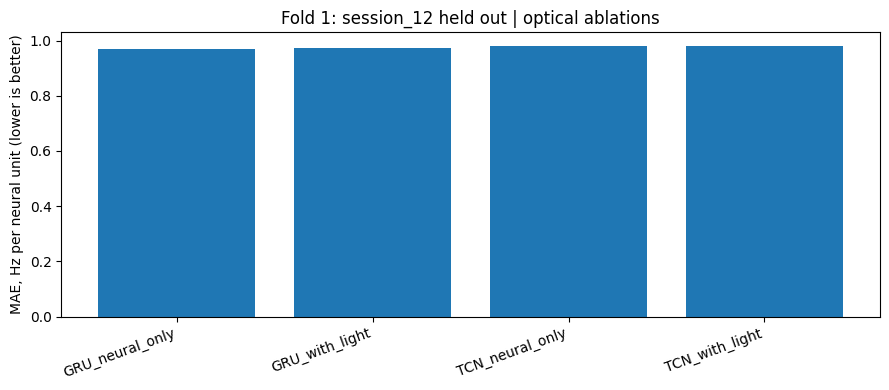

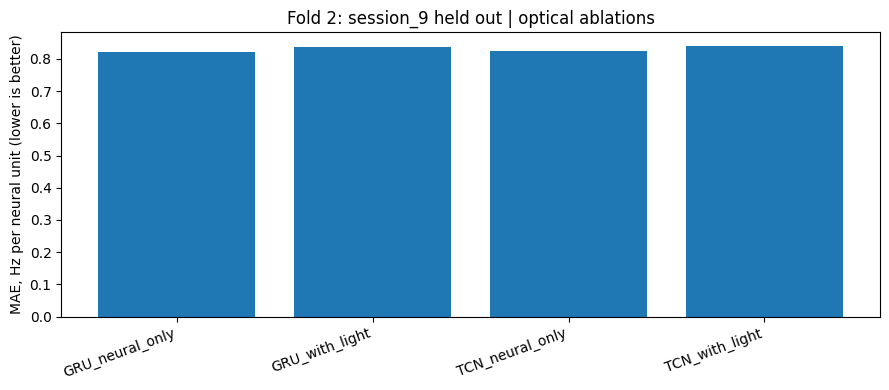

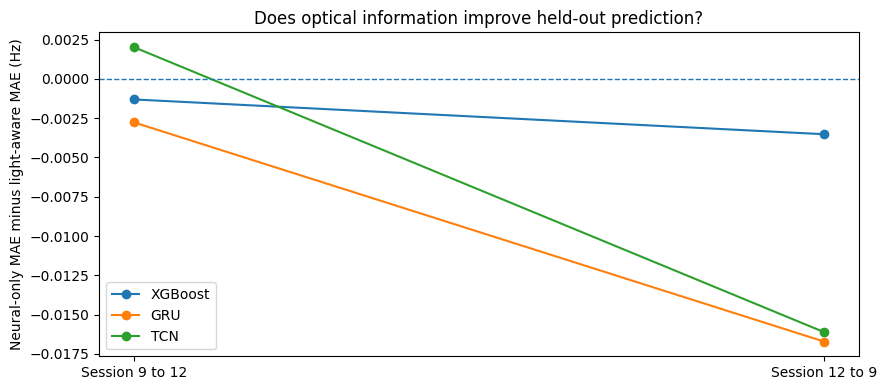

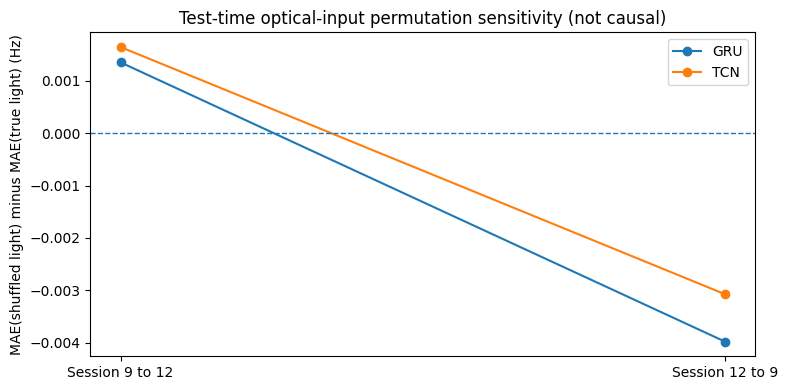

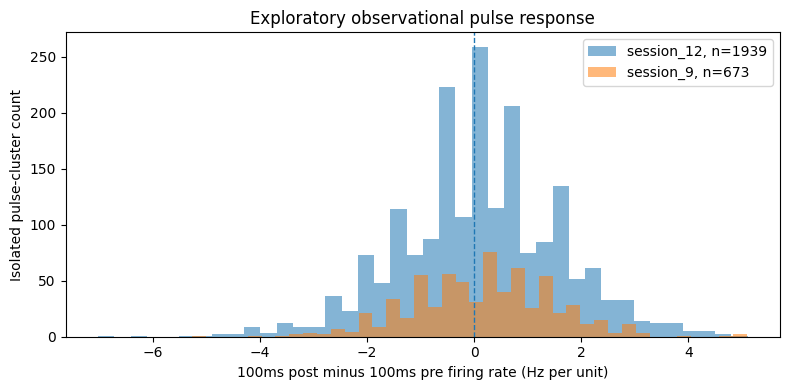

In [9]:
for fold in sorted(results.fold.unique()):
    sub=results[(results.fold==fold)&(results.group=='ALL')]
    cols=['GRU_neural_only','GRU_with_light','TCN_neural_only','TCN_with_light']
    vals=[float(sub.loc[sub.model==m,'MAE_Hz'].iloc[0]) for m in cols]
    fig,ax=plt.subplots(figsize=(9,4))
    ax.bar(range(len(cols)),vals)
    ax.set_xticks(range(len(cols)),cols,rotation=20,ha='right')
    ax.set_ylabel('MAE, Hz per neural unit (lower is better)')
    ax.set_title(f'Fold {fold}: {sub.test_session.iloc[0]} held out | optical ablations')
    fig.tight_layout();fig.savefig(OUT/f'fig_fold{fold}_DL_light_ablation.png',dpi=190);plt.show()

fig,ax=plt.subplots(figsize=(9,4))
for arch in ['XGBoost','GRU','TCN']:
    s=paired_delta[paired_delta.architecture==arch]
    ax.plot(s.fold,s.delta_MAE_Hz,'o-',label=arch)
ax.axhline(0,ls='--',linewidth=1)
ax.set_xticks([1,2],['Session 9 to 12','Session 12 to 9'])
ax.set_ylabel('Neural-only MAE minus light-aware MAE (Hz)')
ax.set_title('Does optical information improve held-out prediction?')
ax.legend();fig.tight_layout();fig.savefig(OUT/'fig_paired_optical_benefit.png',dpi=190);plt.show()

fig,ax=plt.subplots(figsize=(8,4))
for arch in ['GRU','TCN']:
    s=negative_control[negative_control.model==arch]
    ax.plot(s.fold,s.shuffled_minus_original_MAE_Hz,'o-',label=arch)
ax.axhline(0,ls='--',linewidth=1)
ax.set_xticks([1,2],['Session 9 to 12','Session 12 to 9'])
ax.set_ylabel('MAE(shuffled light) minus MAE(true light) (Hz)')
ax.set_title('Test-time optical-input permutation sensitivity (not causal)')
ax.legend();fig.tight_layout();fig.savefig(OUT/'fig_light_shuffle_sensitivity.png',dpi=190);plt.show()

fig,ax=plt.subplots(figsize=(8,4))
for label,d in zip(sorted(sessions),PULSE_DETAILS):
    if len(d):
        sample=d.post_minus_pre_Hz.to_numpy()
        ax.hist(sample,bins=40,alpha=0.55,label=f'{label}, n={len(sample)}')
ax.axvline(0,ls='--',linewidth=1)
ax.set_xlabel('100ms post minus 100ms pre firing rate (Hz per unit)')
ax.set_ylabel('Isolated pulse-cluster count')
ax.set_title('Exploratory observational pulse response')
ax.legend();fig.tight_layout();fig.savefig(OUT/'fig_isolated_pulse_pre_post_distribution.png',dpi=190);plt.show()

## 10 | Summary, validity checklist, and output ZIP

**Interpretation requirements** before considering a digital twin:

1. The optical-aware GRU/TCN should beat the exact same architectures with masked light input **in both directions**, preferably with intervals that do not cross zero. Small gains may still reflect experimental timing confounds.
2. Optical permutation sensitivity should be positive in both folds; a zero response would suggest little reliance on optical features. **Permutation is out of distribution**, so a positive response is not sufficient evidence of optical-response learning.
3. Plot and interpret errors separately for windows with recorded light, without light, and with high firing rates. Check whether benefits survive small protocol variations.
4. Do **not** pool folds to compute confidence intervals as if they were independent animals. Even the within-session block bootstrap is exploratory.
5. Both folds are one mouse and the units are not identity-matched; performance cannot yet support personalized epilepsy neuromodulation.

In [10]:
config={'dataset':'DANDI 000568','pinned_version':VERSION,
        'date_utc':datetime.now(timezone.utc).isoformat(),
        'quick_mode':QUICK_MODE,'epochs_max':EPOCHS,'sample_caps':CAPS,
        'folds':FOLDS,'random_seed':SEED,
        'history_sec':BIN_SEC*HISTORY_BINS,'horizon_sec':BIN_SEC*HORIZON_BINS,
        'target':'future population firing rate, Hz per sorted unit',
        'action_input':'observed optical ON fraction in target window, not counterfactual control',
        'light_history_included':True,
        'ablation':'all optical channels zeroed after train-fitted standardization',
        'confidence_interval':'paired 30-second block bootstrap on each test session; NOT animal-level inference',
        'optical_permutation':'test-time input sensitivity only; out-of-distribution, not causal',
        'units':'recording-specific sorted units; identity not matched between sessions',
        'independent_animals':1,
        'limitations':['Both sessions are the same mouse.','No human epilepsy data.',
          'Stimulation amplitude codes not calibrated as power.',
          'Timestamp ranges overlap but perfect synchronization is not independently proven.',
          'Observed future light is conditioned-on; not a chosen future action.',
          'Overlapping pulses and neural-state-dependent protocol timing may confound results.',
          'Time-binned windows and pulses are not independent biological experiments.',
          'Fitted models predict rates, not closed-loop control efficacy.']}
(OUT/'research_config_and_limitations.json').write_text(json.dumps(config,indent=2))
(OUT/'study_readme.txt').write_text(
    'PHASE 2B | CONDITIONAL OPTICAL-RESPONSE PREDICTION\n'
    'All CSV/PNG metrics generated on actual DANDI data in Kaggle.\n'
    'The two recording sessions come from ONE MOUSE. Not cross-animal validation.\n'
    'Primary table: paper_metrics_by_session_and_group.csv\n'
    'Matched ablation: paired_optical_benefit_block_bootstrap.csv\n'
    'Input permutation: shuffled_optical_inputs_sensitivity.csv\n'
    'Experimental responses: isolated_pulse_before_after_EXPLORATORY.csv\n'
    'Evaluate models by fold and subgroup. Do NOT present these as causal stimulation effects.\n'
)
archive=ROOT/'phase2b_optical_validation_results.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for f in OUT.iterdir():
        if f.is_file(): z.write(f,arcname=f.name)
print('\nFINISHED:',archive,'MB:',round(archive.stat().st_size/1e6,2))
print('Upload phase2b_optical_validation_results.zip here for our next research decision.')


FINISHED: /kaggle/working/phase2b_optical_validation_results.zip MB: 1.96
Upload phase2b_optical_validation_results.zip here for our next research decision.
